## Text Embeddings Based Sentiment Classification

This notebook implements sentiment classification using Sentence Transformers embeddings.

## 1. Import Required Libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sentence_transformers import SentenceTransformer
from wordcloud import WordCloud

In [14]:
from google.colab import files

uploaded = files.upload()

Saving Tweets[1].csv to Tweets[1] (1).csv


## 2. Load Dataset

In [15]:
import pandas as pd
import io

# Read whichever CSV file you uploaded
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Display the dataset
print("File loaded:", filename)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

File loaded: Tweets[1] (1).csv
Dataset shape: (27481, 4)
Columns: ['textID', 'text', 'selected_text', 'sentiment']


,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


## 3. Data Preprocessing

In [16]:
df.dropna(inplace=True)
df['text'] = df['text'].str.lower()
df.head()

,textID,text,selected_text,sentiment
0,cb774db0d1,"i`d have responded, if i were going","I`d have responded, if I were going",neutral
1,549e992a42,sooo sad i will miss you here in san diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


## 4. Sentiment Distribution Plot

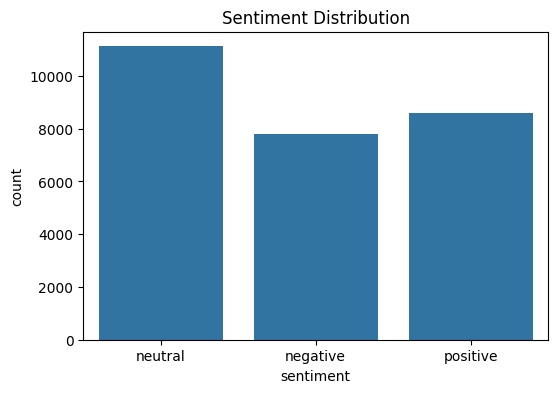

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(x='sentiment', data=df)
plt.title('Sentiment Distribution')
plt.show()

## 5. Word Clouds

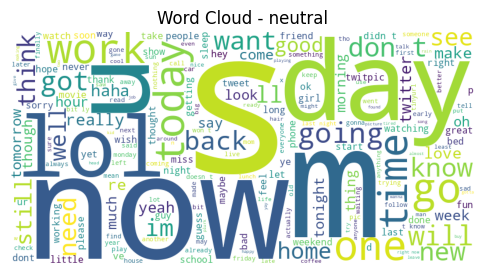

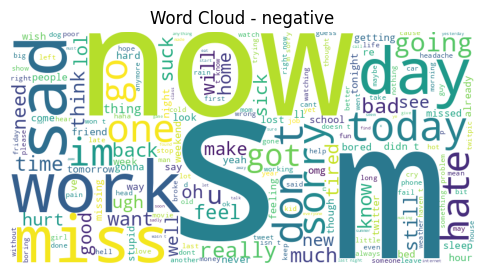

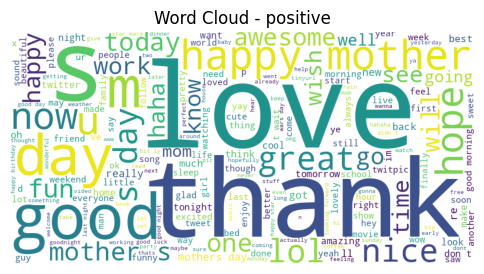

In [18]:
for sentiment in df['sentiment'].unique():
    text = ' '.join(df[df['sentiment'] == sentiment]['text'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(6,4))
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.title(f'Word Cloud - {sentiment}')
    plt.show()

## 6. Text Length Analysis

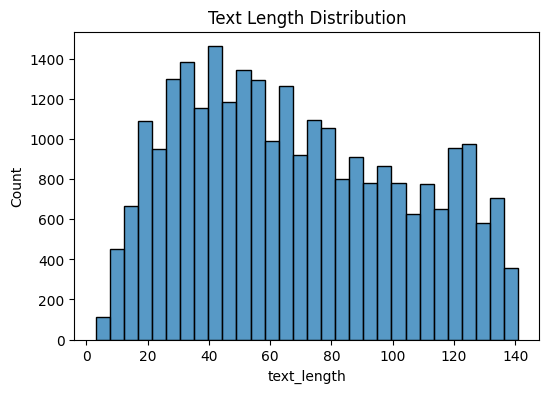

In [19]:
df['text_length'] = df['text'].apply(len)
plt.figure(figsize=(6,4))
sns.histplot(df['text_length'], bins=30)
plt.title('Text Length Distribution')
plt.show()

## 7. Generate Sentence Embeddings

In [20]:
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df['text'].tolist())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 8. Train-Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    embeddings, df['sentiment'], test_size=0.2, random_state=42
)

## 9. Train Logistic Regression Model

In [22]:
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## 10. Model Evaluation

In [23]:
y_pred = clf.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6861353711790393
              precision    recall  f1-score   support

    negative       0.68      0.63      0.66      1572
     neutral       0.64      0.70      0.67      2236
    positive       0.76      0.72      0.74      1688

    accuracy                           0.69      5496
   macro avg       0.69      0.68      0.69      5496
weighted avg       0.69      0.69      0.69      5496



## 11. Confusion Matrix

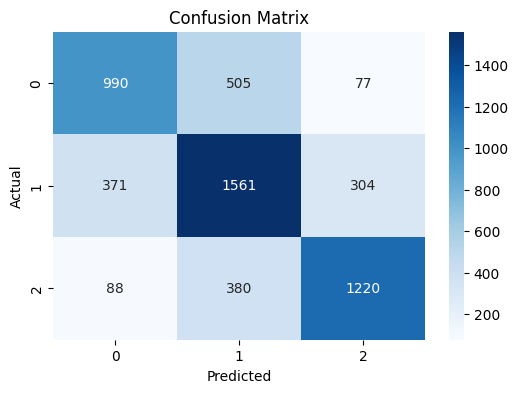

In [24]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 12. Custom Tweet Sentiment Predictions

In [25]:
custom_tweets = [
    "I absolutely love this product!",
    "This is a terrible experience.",
    "The meeting starts at 10 AM tomorrow.",
    "The service was excellent and the staff were friendly.",
    "I am disappointed with the poor quality."
]

clean_tweets = [
    tweet.lower().strip()
    for tweet in custom_tweets
]

custom_embeddings = model.encode(clean_tweets)

custom_predictions = clf.predict(custom_embeddings)

custom_probabilities = clf.predict_proba(custom_embeddings)

custom_results = pd.DataFrame({
    'Tweet': custom_tweets,
    'Predicted Sentiment': custom_predictions,
    'Estimated Confidence (%)': (
        custom_probabilities.max(axis=1) * 100
    ).round(2)
})

display(custom_results)

,Tweet,Predicted Sentiment,Estimated Confidence (%)
0,I absolutely love this product!,positive,98.38
1,This is a terrible experience.,negative,99.24
2,The meeting starts at 10 AM tomorrow.,neutral,82.89
3,The service was excellent and the staff were f...,positive,98.69
4,I am disappointed with the poor quality.,negative,97.83


## 13. Cosine Similarity-Based Sentiment Analysis

In [26]:
from sklearn.metrics.pairwise import cosine_similarity

y_train_array = y_train.to_numpy()
class_labels = clf.classes_

class_centroids = np.vstack([
    X_train[y_train_array == label].mean(axis=0)
    for label in class_labels
])

similarity_scores = cosine_similarity(
    custom_embeddings,
    class_centroids
)

similarity_table = pd.DataFrame(
    similarity_scores,
    columns=[
        f'{label} Similarity'
        for label in class_labels
    ]
)

similarity_table.insert(0, 'Tweet', custom_tweets)
display(similarity_table.round(3))

similarity_predictions = class_labels[
    similarity_scores.argmax(axis=1)
]

similarity_results = pd.DataFrame({
    'Tweet': custom_tweets,
    'Logistic Regression Prediction': custom_predictions,
    'Cosine Similarity Prediction': similarity_predictions
})

display(similarity_results)

,Tweet,negative Similarity,neutral Similarity,positive Similarity
0,I absolutely love this product!,0.204,0.249,0.374
1,This is a terrible experience.,0.400,0.272,0.214
2,The meeting starts at 10 AM tomorrow.,0.211,0.294,0.242
3,The service was excellent and the staff were f...,0.140,0.190,0.272
4,I am disappointed with the poor quality.,0.276,0.219,0.216


,Tweet,Logistic Regression Prediction,Cosine Similarity Prediction
0,I absolutely love this product!,positive,positive
1,This is a terrible experience.,negative,negative
2,The meeting starts at 10 AM tomorrow.,neutral,neutral
3,The service was excellent and the staff were f...,positive,positive
4,I am disappointed with the poor quality.,negative,negative


## Conclusion
This project demonstrates sentiment classification using text embeddings.
The model performs well overall with slight confusion between neutral and negative classes.